# Stage 2 — visual attention through frontal–visual synchrony

This stage replaces the previous generic Stage 2 with a targeted visual-attention experiment. It uses the original 40-area `model_class.Model` rate network and its anatomical FLN matrix, plus the existing CTC phase-gating extension. V4 receives the visual stimulus; area 8l is a provisional frontal attention-control candidate; V1, V2, and V4 form the visual/occipital readout group.

The attentional cue is represented by a small external current to the selected frontal area and task-dependent strengthening of phase coupling. Compare anatomical FLN phase coupling, a shared-rhythm control, and an ungated rate-only control. All conditions keep the same anatomical rate connections active; only phase dynamics and phase gating differ. Workspace re-entry is off in every condition so it cannot explain visual modulation.

This is a first-pass model of attention-related routing, not a spatial-selection model. The current cortical areas do not contain attended and unattended visual locations as separate populations. A later extension should duplicate visual channels if we want to test selective attention between competing targets.


## Step 1 — load the original model and inspect area labels

The 40-area connectivity file stores `FLN[target, source]`: the entry in row *i*, column *j* describes a projection from area *j* to area *i*. We use 8l provisionally as a frontal control node because it has directed links with V4 in this atlas; verify this anatomical mapping against your course material before treating it as definitively prefrontal. The code prints both directions rather than assuming reciprocity.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from brian2 import Hz, pA

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model_class.py').exists()), None)
if project_root is None:
    raise RuntimeError('Run Jupyter from the repository or a subdirectory.')
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(project_root / 'project_experiment'))
from original_model_runner import _base_params, run_original_model
from ctc_validation import _mutual_information_bits

experiment_dir = project_root / 'project_experiment'
base_network = _base_params()
anatomy_path = project_root / 'data' / base_network['connectivity_file']
anatomy = np.load(anatomy_path, allow_pickle=True, encoding='bytes')
area_names = [x.decode() if isinstance(x, bytes) else str(x) for x in anatomy[b'area_list']]
fln_raw = np.asarray(anatomy[b'fln'], dtype=float)

FRONTAL_AREA = '8l'  # provisional frontal attention-control candidate
VISUAL_AREAS = ['V1', 'V2', 'V4']
VISUAL_STIMULUS_AREA = 'V4'
required = [FRONTAL_AREA, *VISUAL_AREAS]
missing = [a for a in required if a not in area_names]
if missing:
    raise ValueError(f'Areas absent from this connectivity atlas: {missing}')
frontal_idx = area_names.index(FRONTAL_AREA)
pair_rows = []
for visual in VISUAL_AREAS:
    visual_idx = area_names.index(visual)
    pair_rows.append({
        'frontal_area': FRONTAL_AREA,
        'visual_area': visual,
        'FLN_frontal_to_visual': float(fln_raw[visual_idx, frontal_idx]),
        'FLN_visual_to_frontal': float(fln_raw[frontal_idx, visual_idx]),
    })
fln_direction_table = pd.DataFrame(pair_rows)
display(fln_direction_table)
print(f'Loaded {len(area_names)} areas from {anatomy_path.name}; matrix convention: FLN[target, source].')


,frontal_area,visual_area,FLN_frontal_to_visual,FLN_visual_to_frontal
0,8l,V1,0.000236,0.000061
1,8l,V2,0.000105,0.003532
2,8l,V4,0.002650,0.012863


Loaded 40 areas from subgraph_data40.pkl; matrix convention: FLN[target, source].


## Step 2 — specify the attention-coupling comparison

- **Anatomical FLN coupling:** phase interactions among 8l, V1, V2, and V4 use their directed FLN weights; only FLN links within this selected group receive the dynamic phase gate.
- **Common rhythm:** the same selected areas are driven by a shared rhythm, while anatomical rate pathways remain on. This tests whether synchrony alone from a shared clock explains the result.
- **Rate-only control:** phases run uncoupled and the selected rate links are ungated, preserving the same anatomical rate network.

The visual stimulus and the 8l cue occur over the same 50–1050 ms interval. The cue current is 50 pA as a provisional starting value; it is not the validated 50 pA workspace-maintenance current. No workspace feedback is enabled here. The small pilot uses four paired seeds and runs 24 trials.


In [2]:
STIM_ON_MS = 50.0
STIM_OFF_MS = 1050.0
RUN_DURATION_MS = 1600.0
VISUAL_STIMULUS_P_A = 500.0
FRONTAL_CUE_CURRENT_P_A = 50.0  # provisional cue input to 8l; tune independently
TASK_COUPLING_GAIN = 0.5
K_RAD_S = 10.8
GATE_DEPTH = 1.0
GAMMA_HZ = 40.0
PHASE_AREAS = [FRONTAL_AREA, *VISUAL_AREAS]
SEEDS = [1, 6, 12, 23]
RUN_PILOT = True  # set True to run 3 phase conditions × 2 cue states × 4 seeds = 24 trials

PHASE_CONDITIONS = {
    'anatomical_FLN': {'phase_mode_override': 'fln', 'phase_gate_strength': GATE_DEPTH, 'K_rad_s': K_RAD_S},
    'common_rhythm': {'phase_mode_override': 'common', 'phase_gate_strength': GATE_DEPTH, 'K_rad_s': K_RAD_S},
    'rate_only': {'phase_mode_override': 'uncoupled', 'phase_gate_strength': 0.0, 'K_rad_s': 0.0},
}
PHASE_FREQUENCIES = {
    FRONTAL_AREA: GAMMA_HZ,
    **{area: GAMMA_HZ + 0.3 for area in VISUAL_AREAS},
}
print('All conditions preserve long-range FLN rate connections.')
print('CTC phase coupling/gating is confined to:', ', '.join(PHASE_AREAS))
print('Workspace re-entry current: 0 pA in every condition.')
print('Pilot enabled:', RUN_PILOT, '| expected trials:', len(PHASE_CONDITIONS) * 2 * len(SEEDS))


All conditions preserve long-range FLN rate connections.
CTC phase coupling/gating is confined to: 8l, V1, V2, V4
Workspace re-entry current: 0 pA in every condition.
Pilot enabled: True | expected trials: 24


## Step 3 — define readouts

Mean phase coherence (MPC) is computed directly from the model's oscillator phases: `abs(mean(exp(1j * phase_difference)))`. No Hilbert transform is needed because the CTC extension already supplies a phase for each modeled area.

The primary readouts are frontal–V4 MPC, V4 firing rate, and the gated 8l→V4 excitatory current. PFC-to-V4 rate mutual information is a secondary association measure. The attention effect is the cue-on minus cue-off change within each phase condition.


In [3]:
def _shift_corrected_mi(x, y, seed, n_shifts=10, bins=6):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    raw = _mutual_information_bits(x, y, bins=bins)
    if len(x) < 40:
        return raw
    rng = np.random.default_rng(int(seed) + 71_000)
    lo, hi = max(10, len(x)//10), max(11, 9*len(x)//10)
    null = [_mutual_information_bits(x, np.roll(y, int(s)), bins=bins)
            for s in rng.integers(lo, hi, size=n_shifts)]
    return max(0.0, float(raw - np.mean(null)))


def _trial_metrics(result, seed, phase_condition, cue_on):
    model = result['model']
    names = [x.decode() if isinstance(x, bytes) else str(x) for x in model.network_params[b'area_list']]
    t = np.asarray(result['time_ms'], dtype=float)
    during = (t >= STIM_ON_MS) & (t < STIM_OFF_MS)
    pfc_i = names.index(FRONTAL_AREA)
    visual_idx = [names.index(a) for a in VISUAL_AREAS]
    v4_i = names.index(VISUAL_STIMULUS_AREA)
    phases = np.asarray(model.get_phase(), dtype=float)
    rates = np.asarray(model.get_r(1) / Hz, dtype=float)
    pfc_v4_delta = phases[:, pfc_i] - phases[:, v4_i]
    pfc_visual_mpc = [abs(np.exp(1j*(phases[during, pfc_i]-phases[during, j])).mean())
                      for j in visual_idx]

    # Isolate the direct 8l -> V4 excitatory pathway contribution; the
    # population model stores matrices in target-by-source orientation.
    gate = np.asarray(model.get_phase_gate(), dtype=float)
    pfc_to_v4 = (
        model.s_1n[:, pfc_i] * model.w_e_n[v4_i, pfc_i]
        + model.s_1a[:, pfc_i] * model.w_e_a[v4_i, pfc_i]
    ) * gate[:, v4_i, pfc_i]
    pfc_to_v4_pA = np.asarray(pfc_to_v4 / pA, dtype=float)

    return {
        'seed': int(seed), 'phase_condition': phase_condition, 'attention_cue_on': bool(cue_on),
        'MPC_8l_V4': float(abs(np.exp(1j*pfc_v4_delta[during]).mean())),
        'MPC_8l_visual_mean': float(np.mean(pfc_visual_mpc)),
        'MI_8l_V4_shift_corrected_bits': _shift_corrected_mi(
            rates[during, pfc_i], rates[during, v4_i], seed
        ),
        'mean_8l_rate_hz': float(rates[during, pfc_i].mean()),
        'mean_V1_rate_hz': float(rates[during, names.index('V1')].mean()),
        'mean_V2_rate_hz': float(rates[during, names.index('V2')].mean()),
        'mean_V4_rate_hz': float(rates[during, v4_i].mean()),
        'mean_gated_8l_to_V4_current_pA': float(pfc_to_v4_pA[during].mean()),
        'max_single_visual_rate_hz': float(rates[:, visual_idx].max()),
    }


## Step 4 — run or resume the paired pilot

Set `RUN_PILOT=True` above to start the scan. The code checkpoints after every trial and writes only to `stage2_visual_attention_pilot_*`, keeping Stage 1 and Stage 3 results separate.


In [4]:
trial_path = experiment_dir / 'stage2_visual_attention_pilot_trials.csv'
trial_rows = []
completed = set()
if trial_path.exists():
    prior = pd.read_csv(trial_path)
    prior = prior[
        prior['seed'].isin(SEEDS)
        & prior['phase_condition'].isin(PHASE_CONDITIONS)
        & prior['attention_cue_on'].isin([False, True])
    ].drop_duplicates(['phase_condition', 'attention_cue_on', 'seed'], keep='last')
    trial_rows.extend(prior.to_dict('records'))
    completed = {(str(r['phase_condition']), bool(r['attention_cue_on']), int(r['seed']))
                 for r in trial_rows}

if RUN_PILOT:
    from tqdm.auto import tqdm
    progress = tqdm(total=len(PHASE_CONDITIONS)*2*len(SEEDS), initial=len(completed),
                    desc='Stage 2 visual-attention pilot', unit='run')
    for phase_label, phase_cfg in PHASE_CONDITIONS.items():
        for cue_on in (False, True):
            for seed in SEEDS:
                key = (phase_label, cue_on, int(seed))
                if key in completed:
                    continue
                cue_current = FRONTAL_CUE_CURRENT_P_A if cue_on else 0.0
                task_gain = TASK_COUPLING_GAIN if cue_on else 0.0
                params = {
                    'duration_ms': RUN_DURATION_MS, 'dt_ms': 0.5,
                    'stim_on_ms': STIM_ON_MS, 'stim_off_ms': STIM_OFF_MS,
                    'stimulus_current_pA': VISUAL_STIMULUS_P_A,
                    'sensory_area': VISUAL_STIMULUS_AREA,
                    'workspace_areas': VISUAL_AREAS,
                    'attention_control_area': FRONTAL_AREA,
                    'attention_control_current_pA': cue_current,
                    'attention_control_on_ms': STIM_ON_MS,
                    'attention_control_off_ms': STIM_OFF_MS,
                    'attention_mode': 'synchrony', 'task_gain': task_gain,
                    'phase_frequency_overrides_hz': PHASE_FREQUENCIES,
                    'phase_network_areas': PHASE_AREAS,
                    'phase_gate_areas': PHASE_AREAS,
                    'phase_coupling_rad_s': phase_cfg['K_rad_s'],
                    'phase_gate_strength': phase_cfg['phase_gate_strength'],
                    'phase_mode_override': phase_cfg['phase_mode_override'],
                    'common_frequency_hz': GAMMA_HZ,
                    'g_sw': 0.95,
                    'workspace_reentry_current_pA': 0.0,
                    'ignition_threshold_hz': 20.0,
                    'ignition_duration_ms': 50.0,
                }
                result = run_original_model(seed=int(seed), params=params, configuration='A')
                row = _trial_metrics(result, seed, phase_label, cue_on)
                row.update({
                    'frontal_cue_current_pA': cue_current,
                    'task_coupling_gain': task_gain,
                    'K_rad_s': phase_cfg['K_rad_s'],
                    'phase_gate_depth': phase_cfg['phase_gate_strength'],
                    'frontal_area': FRONTAL_AREA,
                    'visual_areas': ','.join(VISUAL_AREAS),
                })
                trial_rows.append(row); completed.add(key)
                pd.DataFrame(trial_rows).to_csv(trial_path, index=False)
                progress.update(1)
    progress.close()
    print(f'Saved {len(trial_rows)} trial rows to {trial_path}')
elif trial_rows:
    print(f'Pilot scan is off. Found {len(trial_rows)} saved rows; set RUN_PILOT=True to resume or extend.')
else:
    print('Pilot scan is off. Set RUN_PILOT=True to run the 24-trial pilot.')


Stage 2 visual-attention pilot: 100%|##########| 24/24 [00:00<?, ?run/s]

Saved 24 trial rows to D:\Project\pythonProject\atoum-master\project_experiment\stage2_visual_attention_pilot_trials.csv


## Step 5 — summarize the visual-attention effects

Use paired seeds and compare cue-on versus cue-off within each phase condition. A larger MPC without a change in visual response or gated PFC→V4 input is synchronization without demonstrated attentional benefit. The shared-rhythm condition is especially useful for checking that high MPC alone does not guarantee effective signal transfer.


In [5]:
if trial_rows:
    trials = pd.DataFrame(trial_rows).drop_duplicates(
        ['phase_condition', 'attention_cue_on', 'seed'], keep='last'
    )
    summary = trials.groupby(['phase_condition', 'attention_cue_on']).agg(
        n=('seed', 'nunique'),
        mean_MPC_8l_V4=('MPC_8l_V4', 'mean'),
        mean_MPC_8l_visual=('MPC_8l_visual_mean', 'mean'),
        mean_MI_bits=('MI_8l_V4_shift_corrected_bits', 'mean'),
        mean_8l_rate_hz=('mean_8l_rate_hz', 'mean'),
        mean_V4_rate_hz=('mean_V4_rate_hz', 'mean'),
        mean_8l_to_V4_current_pA=('mean_gated_8l_to_V4_current_pA', 'mean'),
        max_visual_area_rate_hz=('max_single_visual_rate_hz', 'max'),
    ).reset_index()
    display(summary.round(3))
    summary.to_csv(experiment_dir / 'stage2_visual_attention_pilot_summary.csv', index=False)

    paired_rows = []
    for phase_label, block in trials.groupby('phase_condition'):
        on = block[block.attention_cue_on].set_index('seed')
        off = block[~block.attention_cue_on].set_index('seed')
        common = on.index.intersection(off.index)
        for metric in ['MPC_8l_V4', 'mean_V4_rate_hz',
                       'mean_gated_8l_to_V4_current_pA', 'MI_8l_V4_shift_corrected_bits']:
            paired_rows.append({
                'phase_condition': phase_label, 'metric': metric, 'n_paired_seeds': len(common),
                'cue_on_mean': float(on.loc[common, metric].mean()),
                'cue_off_mean': float(off.loc[common, metric].mean()),
                'cue_on_minus_off': float((on.loc[common, metric]-off.loc[common, metric]).mean()),
            })
    paired = pd.DataFrame(paired_rows)
    display(paired.round(4))
    paired.to_csv(experiment_dir / 'stage2_visual_attention_pilot_paired_effects.csv', index=False)
else:
    print('Run Step 4 first to create trial data.')


,phase_condition,attention_cue_on,n,mean_MPC_8l_V4,mean_MPC_8l_visual,mean_MI_bits,mean_8l_rate_hz,mean_V4_rate_hz,mean_8l_to_V4_current_pA,max_visual_area_rate_hz
0,anatomical_FLN,False,4,0.995,0.979,0.093,3.960,114.014,9.068,122.818
1,anatomical_FLN,True,4,0.996,0.986,0.109,28.998,113.192,64.253,122.664
2,common_rhythm,False,4,0.995,0.971,0.115,3.959,114.015,9.063,122.815
3,common_rhythm,True,4,0.997,0.979,0.114,28.991,113.193,64.207,122.665
4,rate_only,False,4,0.858,0.858,0.000,3.584,93.948,4.240,112.612
5,rate_only,True,4,0.858,0.858,0.257,28.761,97.158,32.031,115.035


,phase_condition,metric,n_paired_seeds,cue_on_mean,cue_off_mean,cue_on_minus_off
0,anatomical_FLN,MPC_8l_V4,4,0.9962,0.9947,0.0015
1,anatomical_FLN,mean_V4_rate_hz,4,113.1920,114.0140,-0.8219
2,anatomical_FLN,mean_gated_8l_to_V4_current_pA,4,64.2529,9.0678,55.1851
3,anatomical_FLN,MI_8l_V4_shift_corrected_bits,4,0.1094,0.0934,0.0160
4,common_rhythm,MPC_8l_V4,4,0.9965,0.9951,0.0014
5,common_rhythm,mean_V4_rate_hz,4,113.1931,114.0150,-0.8219
6,common_rhythm,mean_gated_8l_to_V4_current_pA,4,64.2071,9.0629,55.1442
7,common_rhythm,MI_8l_V4_shift_corrected_bits,4,0.1136,0.1152,-0.0016
8,rate_only,MPC_8l_V4,4,0.8584,0.8584,0.0000
9,rate_only,mean_V4_rate_hz,4,97.1577,93.9480,3.2098


## Step 6 — plot synchronization and visual-response changes

These are preliminary four-seed traces and should be treated as a mechanism check. The next expansion should add seeds and, if spatial attention is the target, separate attended and unattended visual channels.


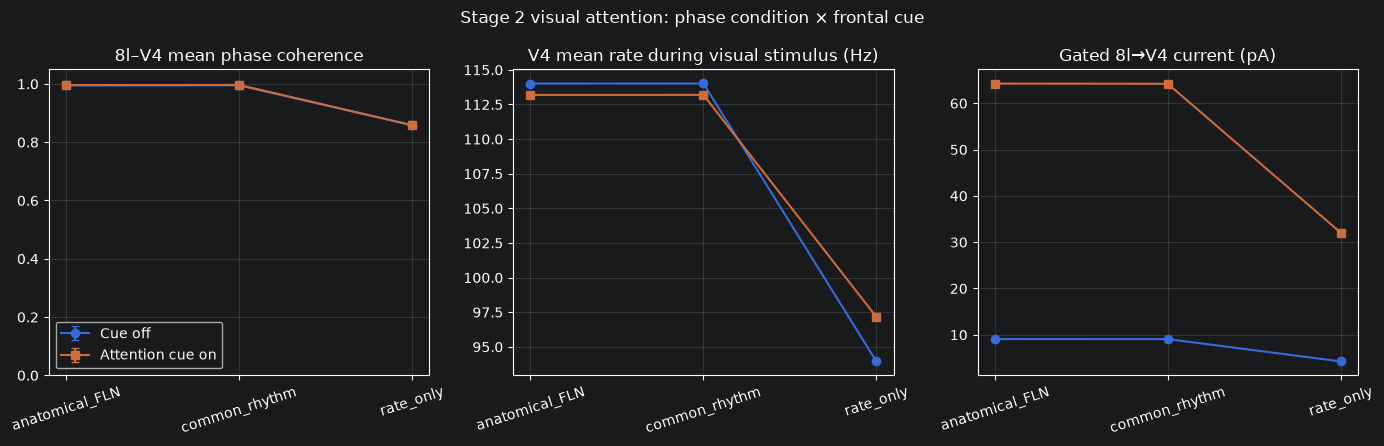

In [6]:
if trial_rows:
    plot_summary = trials.groupby(['phase_condition', 'attention_cue_on']).agg(
        n=('seed','nunique'), MPC=('MPC_8l_V4','mean'), MPC_sd=('MPC_8l_V4','std'),
        V4=('mean_V4_rate_hz','mean'), V4_sd=('mean_V4_rate_hz','std'),
        topdown=('mean_gated_8l_to_V4_current_pA','mean'), topdown_sd=('mean_gated_8l_to_V4_current_pA','std'),
    ).reset_index()
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    metrics = [('MPC','MPC_sd','8l–V4 mean phase coherence'),
               ('V4','V4_sd','V4 mean rate during visual stimulus (Hz)'),
               ('topdown','topdown_sd','Gated 8l→V4 current (pA)')]
    order = list(PHASE_CONDITIONS)
    for ax, (mean_col, sd_col, title) in zip(axes, metrics):
        for cue_on, label, marker in [(False,'Cue off','o'), (True,'Attention cue on','s')]:
            block = plot_summary[plot_summary.attention_cue_on == cue_on].set_index('phase_condition').reindex(order)
            sem = block[sd_col].fillna(0).to_numpy() / np.sqrt(block['n'].to_numpy())
            ax.errorbar(order, block[mean_col], yerr=sem, marker=marker, capsize=3, label=label)
        ax.set_title(title); ax.grid(alpha=.25); ax.tick_params(axis='x', rotation=18)
    axes[0].set_ylim(0, 1.05); axes[0].legend()
    fig.suptitle('Stage 2 visual attention: phase condition × frontal cue')
    fig.tight_layout()
    fig.savefig(experiment_dir / 'stage2_visual_attention_pilot.png', dpi=180, bbox_inches='tight')
    plt.show()
else:
    print('Run Step 4 first to create trial data.')


## What this Stage 2 can and cannot establish

This experiment tests whether attention-like frontal drive changes PFC/visual synchrony and the effectiveness of a real FLN pathway when phase gating is confined to selected frontal and visual areas. The 8l cue current is an external control input to the frontal node; it is not workspace re-entry. The task-gain term increases phase-coupling strength during the cue interval.

The phase oscillators remain an explicit CTC extension and are not generated by the original firing-rate equations. A positive result would show that the added phase-gating mechanism can improve routing in the original network, not prove that biological attention works exactly this way. For a stronger spatial-attention model, the next extension is two visual populations (attended/unattended), an attention cue selecting one of them, and an attention-selectivity index.

Empirical motivation: attention-related long-range coupling has been reported between frontal eye fields and visual area V4, and prefrontal lesions can reduce attentional modulation in V4 ([Gregoriou et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC2849291/); [Gregoriou et al., lesion study](https://www.nature.com/articles/nn.3742)). These findings motivate the model experiment but do not determine its outcome or parameter values.

## Step 7 — refined calibration and attention-factor scan

The first pilot used a strong 500 pA visual stimulus and a 0.3 Hz phase-frequency difference, which drove V4 response and synchrony near their observed ceiling. The refined scan first chooses a lower V4 input (targeting about 40 Hz), then tests a 1 Hz detuning over K=1, 3, 6, and 10.8 rad/s. It finally separates the 8l cue current (0/50 pA) from task-dependent coupling gain (0/0.5). Each phase condition uses the same four paired seeds. All scan outputs use a new `stage2_visual_attention_refined_*` prefix.

To run the three scan phases, execute the code cell below. It checkpoints each completed trial so the run can resume. The attention cue is a provisional current to 8l; it is not the Stage 0 workspace-reentry current.


In [7]:
from run_stage2_visual_attention_refined import run_refined_pilot
RUN_REFINED_SCAN = False  # set True to calibrate, scan K, and separate cue/gain effects
if RUN_REFINED_SCAN:
    run_refined_pilot()
else:
    print('Refined scan is off. Set RUN_REFINED_SCAN=True to start or resume it.')


Refined scan is off. Set RUN_REFINED_SCAN=True to start or resume it.


## Step 8 — inspect refined scan outputs

After Step 7 finishes, read the calibration and coupling tables before interpreting the cue factorial. The selected visual input should leave room for top-down modulation, and the chosen K should avoid MPC values pinned near 1.0.


In [8]:
refined_files = {
    'V4 stimulus calibration': 'stage2_visual_attention_refined_stimulus_summary.csv',
    'phase coupling scan': 'stage2_visual_attention_refined_coupling_summary.csv',
    'cue × coupling factorial': 'stage2_visual_attention_refined_cue_summary.csv',
}
for title, filename in refined_files.items():
    path = experiment_dir / filename
    if path.exists():
        print(title)
        display(pd.read_csv(path).round(3))
    else:
        print(f'{title}: run Step 7 first (missing {filename})')


V4 stimulus calibration


,visual_stimulus_pA,n,mean_V4_rate_hz,sd_V4_rate_hz,mean_8l_rate_hz,max_visual_rate_hz
0,100.0,4,1.413,0.0,0.028,1.551
1,200.0,4,43.079,0.0,1.898,55.860
2,300.0,4,61.098,0.0,2.455,73.622
3,400.0,4,77.719,0.0,3.221,92.034
4,500.0,4,93.948,0.0,3.584,112.612


phase coupling scan


,phase_condition,K_rad_s,n,mean_MPC_8l_V4,sd_MPC_8l_V4,mean_V4_rate_hz,mean_MI_bits
0,anatomical_FLN,1.0,4,0.093,0.030,59.882,0.099
1,anatomical_FLN,3.0,4,0.398,0.180,62.781,0.050
2,anatomical_FLN,6.0,4,0.971,0.028,64.384,0.096
3,anatomical_FLN,10.8,4,0.994,0.006,64.588,0.135
4,common_rhythm,1.0,4,0.266,0.062,59.295,0.063
5,common_rhythm,3.0,4,0.849,0.086,64.441,0.120
6,common_rhythm,6.0,4,0.975,0.028,64.510,0.066
7,common_rhythm,10.8,4,0.994,0.007,64.561,0.121
8,rate_only,0.0,4,0.000,0.000,43.079,0.000


cue × coupling factorial


,phase_condition,pfc_cue_current_pA,task_coupling_gain,n,mean_MPC_8l_V4,mean_8l_rate_hz,mean_V4_rate_hz,mean_8l_to_V4_current_pA,mean_MI_bits,max_visual_rate_hz
0,anatomical_FLN,0.0,0.0,4,0.971,4.665,64.384,8.917,0.096,74.794
1,anatomical_FLN,0.0,0.5,4,0.990,4.704,64.542,9.792,0.110,74.804
2,anatomical_FLN,50.0,0.0,4,0.971,27.668,63.808,45.602,0.006,74.605
3,anatomical_FLN,50.0,0.5,4,0.990,27.727,63.864,55.054,0.031,74.615
4,common_rhythm,0.0,0.0,4,0.975,4.680,64.510,8.991,0.066,74.729
5,common_rhythm,0.0,0.5,4,0.989,4.718,64.535,9.759,0.074,74.750
6,common_rhythm,50.0,0.0,4,0.975,27.619,63.847,47.041,0.050,74.555
7,common_rhythm,50.0,0.5,4,0.989,27.664,63.869,54.407,0.051,74.575
8,rate_only,0.0,0.0,4,0.000,1.898,43.079,2.248,0.000,55.860
9,rate_only,0.0,0.5,4,0.000,1.898,43.079,2.248,0.000,55.860


## Step 9 — fine stimulus, coupling, and detuning scan

This refinement uses four paired seeds. It scans V4 stimulus at 100, 125, 150, 175, and 200 pA; then scans the full K curve (1–6 rad/s) at 1-Hz intrinsic-frequency detuning and adds 2–4 Hz detuning runs around intermediate K values (3 and 4 rad/s), where synchrony is not already at ceiling. Anatomical FLN and common-rhythm conditions use the same seeds so their differences can be evaluated as paired contrasts. The script checkpoints each run to CSV.

Run the cell below once. It can take several minutes; if interrupted, rerunning resumes from the saved CSV rows.

In [9]:
from run_stage2_visual_attention_fine_scan import run_fine_scan
RUN_FINE_SCAN = False  # set True to run the fine paired-seed scan
if RUN_FINE_SCAN:
    run_fine_scan()

## Step 10 — inspect paired contrasts

The contrast is anatomical FLN minus common rhythm for each matched seed. Positive values indicate a larger outcome in the anatomical condition. The 95% intervals are exploratory with four seed pairs; use the individual-seed table to inspect consistency.


### stage2_visual_attention_fine_paired_contrasts.png


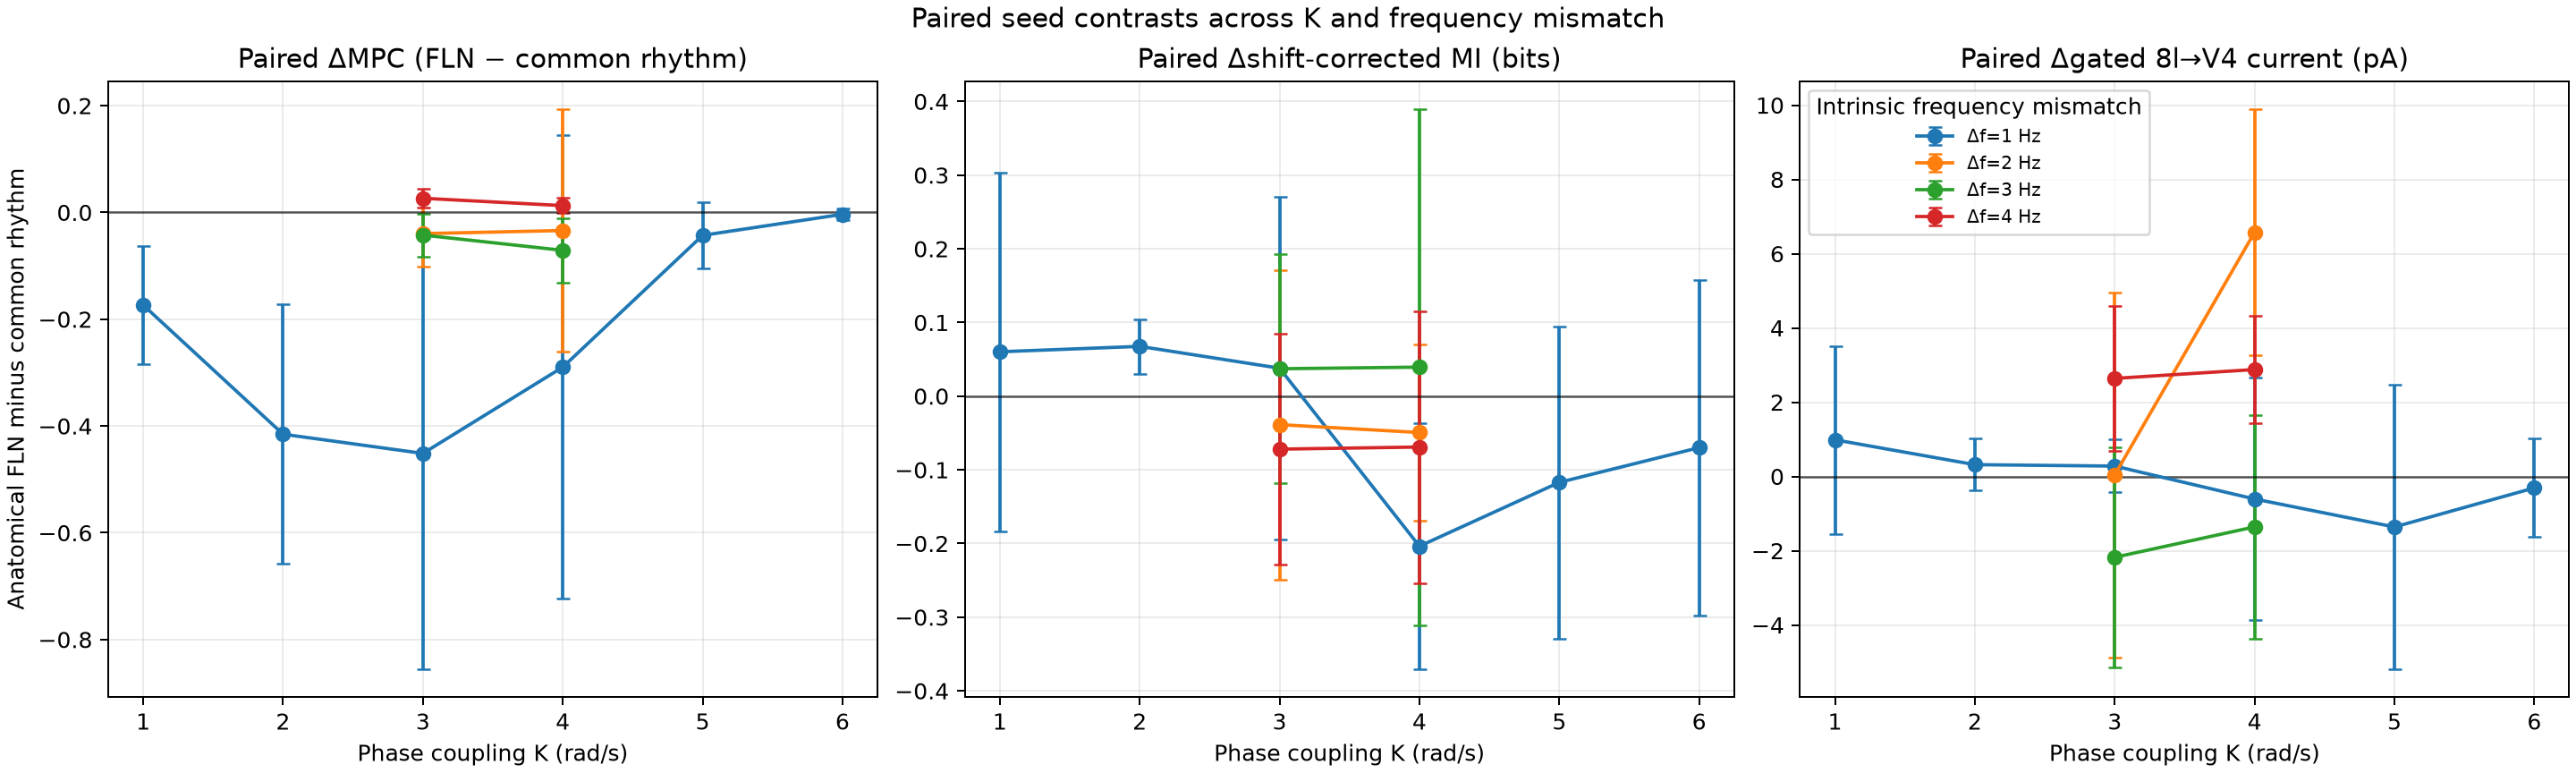


### stage2_visual_attention_fine_stimulus_summary.csv


,phase_condition,visual_stimulus_pA,n,mean_MPC_8l_V4,sd_MPC_8l_V4,mean_V4_rate_hz,mean_8l_rate_hz,mean_MI_bits,max_visual_rate_hz
0,anatomical_FLN,100.0,4,1.418655e-01,3.464268e-02,1.446442,0.027783,0.036580,1.603868
1,anatomical_FLN,125.0,4,1.418655e-01,3.464268e-02,35.518272,4.078075,0.031173,58.047769
2,anatomical_FLN,150.0,4,1.418655e-01,3.464268e-02,48.739240,0.389225,0.209231,65.024439
3,anatomical_FLN,175.0,4,1.418655e-01,3.464268e-02,56.332767,0.917914,0.053475,70.309225
4,anatomical_FLN,200.0,4,1.418655e-01,3.464268e-02,62.344768,1.603736,0.058890,74.738280
5,common_rhythm,100.0,4,1.815795e-01,9.507462e-03,1.429441,0.027419,0.064291,1.592972
6,common_rhythm,125.0,4,1.815795e-01,9.507462e-03,29.146329,3.569130,0.069841,56.880509
7,common_rhythm,150.0,4,1.815795e-01,9.507462e-03,41.880273,0.187838,0.053854,64.819702
8,common_rhythm,175.0,4,1.815795e-01,9.507462e-03,48.897491,0.881119,0.170470,70.174265
9,common_rhythm,200.0,4,1.815795e-01,9.507462e-03,60.551872,1.651328,0.000000,74.660090



### stage2_visual_attention_fine_coupling_summary.csv


,phase_condition,K_rad_s,frequency_detuning_hz,n,mean_MPC_8l_V4,sd_MPC_8l_V4,mean_V4_rate_hz,mean_MI_bits,mean_gated_pathway_current_pA,max_visual_rate_hz
0,anatomical_FLN,1.0,1.0,4,0.092971,0.029943,31.730756,0.141196,1.107793,56.981982
1,anatomical_FLN,2.0,1.0,4,0.222023,0.080488,32.334062,0.089309,0.374633,57.416173
2,anatomical_FLN,3.0,1.0,4,0.397799,0.180391,35.259269,0.081085,0.635096,57.508252
3,anatomical_FLN,3.0,2.0,4,0.141865,0.034643,35.518272,0.031173,7.199660,58.047769
4,anatomical_FLN,3.0,3.0,4,0.089216,0.018169,35.168086,0.140176,3.074688,57.469284
5,anatomical_FLN,3.0,4.0,4,0.064631,0.011051,35.488991,0.061212,3.933520,57.990781
6,anatomical_FLN,4.0,1.0,4,0.638467,0.228136,35.688794,0.046265,2.329216,57.545904
7,anatomical_FLN,4.0,2.0,4,0.200901,0.060455,35.770367,0.000234,7.583127,58.083731
8,anatomical_FLN,4.0,3.0,4,0.117494,0.021862,35.703217,0.148572,1.844308,57.497286
9,anatomical_FLN,4.0,4.0,4,0.084531,0.011677,35.762118,0.071032,4.779581,58.001089



### stage2_visual_attention_fine_paired_contrast_summary.csv


,K_rad_s,frequency_detuning_hz,n_pairs,delta_MPC_8l_V4_mean,delta_MPC_8l_V4_ci95_low,delta_MPC_8l_V4_ci95_high,delta_MPC_8l_V4_positive_seeds,delta_MI_8l_V4_shift_corrected_bits_mean,delta_MI_8l_V4_shift_corrected_bits_ci95_low,delta_MI_8l_V4_shift_corrected_bits_ci95_high,delta_MI_8l_V4_shift_corrected_bits_positive_seeds,delta_mean_V4_rate_hz_mean,delta_mean_V4_rate_hz_ci95_low,delta_mean_V4_rate_hz_ci95_high,delta_mean_V4_rate_hz_positive_seeds,delta_mean_gated_8l_to_V4_current_pA_mean,delta_mean_gated_8l_to_V4_current_pA_ci95_low,delta_mean_gated_8l_to_V4_current_pA_ci95_high,delta_mean_gated_8l_to_V4_current_pA_positive_seeds,anatomical_mean_MPC_8l_V4
0,1.0,1.0,4,-0.173503,-0.283362,-0.063643,0,0.060214,-0.183082,0.303509,3,3.137430,-6.253308,12.528169,3,0.986654,-1.541963,3.515270,4,0.092971
1,2.0,1.0,4,-0.415418,-0.658408,-0.172428,0,0.067562,0.030481,0.104644,4,3.412311,-6.865595,13.690217,4,0.317533,-0.378475,1.013541,3,0.222023
2,3.0,1.0,4,-0.451377,-0.855090,-0.047664,0,0.037961,-0.194752,0.270675,2,6.136216,-5.038318,17.310749,4,0.279379,-0.432306,0.991064,3,0.397799
3,3.0,2.0,4,-0.039714,-0.102104,0.022676,1,-0.038668,-0.248776,0.171440,1,6.371942,-3.397892,16.141776,4,0.040365,-4.867144,4.947875,2,0.141865
4,3.0,3.0,4,-0.042429,-0.082759,-0.002100,0,0.037179,-0.118276,0.192633,2,9.073290,0.220105,17.926475,4,-2.177588,-5.151416,0.796239,0,0.089216
5,3.0,4.0,4,0.026524,0.009445,0.043604,4,-0.071922,-0.228363,0.084520,1,10.137091,0.302795,19.971387,4,2.641313,0.678911,4.603716,4,0.064631
6,4.0,1.0,4,-0.289778,-0.723875,0.144320,0,-0.203687,-0.370294,-0.037081,0,3.316625,-5.714533,12.347783,4,-0.607198,-3.869506,2.655110,2,0.638467
7,4.0,2.0,4,-0.033906,-0.261240,0.193429,2,-0.049384,-0.169494,0.070726,0,3.981999,-6.095727,14.059726,4,6.578776,3.264164,9.893389,4,0.200901
8,4.0,3.0,4,-0.070992,-0.131673,-0.010310,0,0.039379,-0.310783,0.389540,3,9.562250,0.087368,19.037132,4,-1.358613,-4.379171,1.661944,2,0.117494
9,4.0,4.0,4,0.012740,-0.001382,0.026863,4,-0.069065,-0.253700,0.115570,2,10.602617,0.418585,20.786650,4,2.879797,1.429979,4.329614,4,0.084531



### stage2_visual_attention_fine_candidate_conditions.csv


,K_rad_s,frequency_detuning_hz,n_pairs,delta_MPC_8l_V4_mean,delta_MPC_8l_V4_ci95_low,delta_MPC_8l_V4_ci95_high,delta_MPC_8l_V4_positive_seeds,delta_MI_8l_V4_shift_corrected_bits_mean,delta_MI_8l_V4_shift_corrected_bits_ci95_low,delta_MI_8l_V4_shift_corrected_bits_ci95_high,delta_MI_8l_V4_shift_corrected_bits_positive_seeds,delta_mean_V4_rate_hz_mean,delta_mean_V4_rate_hz_ci95_low,delta_mean_V4_rate_hz_ci95_high,delta_mean_V4_rate_hz_positive_seeds,delta_mean_gated_8l_to_V4_current_pA_mean,delta_mean_gated_8l_to_V4_current_pA_ci95_low,delta_mean_gated_8l_to_V4_current_pA_ci95_high,delta_mean_gated_8l_to_V4_current_pA_positive_seeds,anatomical_mean_MPC_8l_V4
0,2.0,1.0,4,-0.415418,-0.658408,-0.172428,0,0.067562,0.030481,0.104644,4,3.412311,-6.865595,13.690217,4,0.317533,-0.378475,1.013541,3,0.222023
1,4.0,2.0,4,-0.033906,-0.261240,0.193429,2,-0.049384,-0.169494,0.070726,0,3.981999,-6.095727,14.059726,4,6.578776,3.264164,9.893389,4,0.200901


In [10]:
from pathlib import Path
fine_names = [
    'stage2_visual_attention_fine_paired_contrasts.png',
    'stage2_visual_attention_fine_stimulus_summary.csv',
    'stage2_visual_attention_fine_coupling_summary.csv',
    'stage2_visual_attention_fine_paired_contrast_summary.csv',
    'stage2_visual_attention_fine_candidate_conditions.csv',
]
for filename in fine_names:
    path = Path('project_experiment') / filename
    print(f'\n### {filename}')
    if path.exists() and path.suffix == '.png':
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    elif path.exists():
        display(pd.read_csv(path))
    else:
        print('Not generated yet; run Step 9 first.')